# Семинар 3. Коллаборативная фильтрация: kNN

**Продолжительность**: 1-1.5 часа.

**Цели**:
- реализовать user-based и item-based cosine kNN;
- сравнить с popularity;
- освоить similarity shrinking, Jaccard, Pearson;


In [1]:
import os
import io
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
import random
random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)


In [2]:
def try_download_movielens_100k(cache_dir='../../assets/data'):
    '''Пытается скачать MovieLens 100K; при ошибке — None.'''
    os.makedirs(cache_dir, exist_ok=True)
    zip_path = os.path.join(cache_dir, 'ml-100k.zip')
    extract_dir = os.path.join(cache_dir, 'ml-100k')
    ratings_file = os.path.join(extract_dir, 'u.data')
    if os.path.exists(ratings_file):
        return ratings_file
    url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
    try:
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(cache_dir)
        return ratings_file if os.path.exists(ratings_file) else None
    except Exception as e:
        print(f'Не удалось скачать: {e}')
        return None


def generate_synthetic_interactions(n_users=500, n_items=800, n_events=30000, seed=RANDOM_STATE):
    '''Синтетический fallback с длинным хвостом и латентной структурой.'''
    rng = np.random.default_rng(seed)
    # степенное распределение популярности
    item_popularity = rng.pareto(1.2, n_items) + 1
    item_popularity /= item_popularity.sum()
    user_activity = rng.pareto(1.1, n_users) + 1
    user_activity /= user_activity.sum()

    users = rng.choice(n_users, size=n_events, p=user_activity)
    items = rng.choice(n_items, size=n_events, p=item_popularity)
    # Латентные факторы: 5 «жанров»
    latent_dim = 5
    U = rng.normal(0, 1, (n_users, latent_dim))
    V = rng.normal(0, 1, (n_items, latent_dim))
    user_bias = rng.normal(0, 0.3, n_users)
    item_bias = rng.normal(0, 0.3, n_items)
    scores = (U[users] * V[items]).sum(axis=1) * 0.3
    ratings = 3 + user_bias[users] + item_bias[items] + scores + rng.normal(0, 0.4, n_events)
    ratings = np.clip(np.round(ratings), 1, 5).astype(int)
    ts_start = 1_500_000_000
    timestamps = ts_start + rng.integers(0, 3_600 * 24 * 200, size=n_events)
    df = pd.DataFrame({
        'user_id': users.astype(int),
        'item_id': items.astype(int),
        'rating': ratings,
        'timestamp': timestamps,
    })
    df = df.drop_duplicates(subset=['user_id', 'item_id'])
    return df.sort_values('timestamp').reset_index(drop=True)


def load_interactions():
    path = try_download_movielens_100k()
    if path is not None:
        cols = ['user_id', 'item_id', 'rating', 'timestamp']
        df = pd.read_csv(path, sep='\t', names=cols)
        print(f'MovieLens 100K: {len(df)} interactions, users={df.user_id.nunique()}, items={df.item_id.nunique()}')
        return df
    print('Используем синтетический датасет.')
    df = generate_synthetic_interactions()
    print(f'Synthetic: {len(df)} interactions, users={df.user_id.nunique()}, items={df.item_id.nunique()}')
    return df

df = load_interactions()
df.head()


MovieLens 100K: 100000 interactions, users=943, items=1682


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
def temporal_split(df, test_frac=0.2, val_frac=0.0):
    df_sorted = df.sort_values('timestamp')
    n = len(df_sorted)
    n_test = int(n * test_frac)
    n_val = int(n * val_frac)
    train = df_sorted.iloc[:n - n_test - n_val].copy()
    val   = df_sorted.iloc[n - n_test - n_val: n - n_test].copy()
    test  = df_sorted.iloc[n - n_test:].copy()
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

train, val, test = temporal_split(df, test_frac=0.2, val_frac=0.1)
print(f'Train: {len(train)}, Val: {len(val)}, Test: {len(test)}')
assert train['timestamp'].max() <= val['timestamp'].min() if len(val) else True
assert (val['timestamp'].max() if len(val) else train['timestamp'].max()) <= test['timestamp'].min()
print('OK: без утечек по времени.')


Train: 70000, Val: 10000, Test: 20000
OK: без утечек по времени.


In [4]:
def positives(df, threshold=4):
    if 'rating' in df.columns and df['rating'].max() > 1:
        return df[df['rating'] >= threshold].copy()
    return df.copy()

train_pos = positives(train)
val_pos   = positives(val)
test_pos  = positives(test)

train_seen_by_user = train.groupby('user_id')['item_id'].apply(set).to_dict()
test_by_user = test_pos.groupby('user_id')['item_id'].apply(set).to_dict()
val_by_user  = val_pos.groupby('user_id')['item_id'].apply(set).to_dict()
print(f'Positive train: {len(train_pos)}, val: {len(val_pos)}, test: {len(test_pos)}')


Positive train: 38968, val: 5104, test: 11303


In [5]:
def precision_at_k(recs, ground_truth, k=10):
    hits = sum(1 for i in recs[:k] if i in ground_truth)
    return hits / k

def recall_at_k(recs, ground_truth, k=10):
    if not ground_truth:
        return 0.0
    hits = sum(1 for i in recs[:k] if i in ground_truth)
    return hits / len(ground_truth)

def hit_rate_at_k(recs, ground_truth, k=10):
    return 1.0 if any(i in ground_truth for i in recs[:k]) else 0.0

def mrr_at_k(recs, ground_truth, k=10):
    for pos, i in enumerate(recs[:k], start=1):
        if i in ground_truth:
            return 1.0 / pos
    return 0.0

def dcg_at_k(recs, ground_truth, k=10):
    return sum(1.0 / np.log2(pos + 1) for pos, i in enumerate(recs[:k], start=1) if i in ground_truth)

def ndcg_at_k(recs, ground_truth, k=10):
    if not ground_truth:
        return 0.0
    dcg = dcg_at_k(recs, ground_truth, k)
    idcg = sum(1.0 / np.log2(pos + 1) for pos in range(1, min(len(ground_truth), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0

def average_precision_at_k(recs, gt, k):
    if not gt: return 0.0
    hits = 0; ap = 0.0
    for pos, i in enumerate(recs[:k], start=1):
        if i in gt:
            hits += 1
            ap += hits / pos
    return ap / min(len(gt), k)

def evaluate(reco_fn, test_by_user, users, k=10, extra_metrics=None):
    metrics = defaultdict(list)
    reco_by_user = {}
    for u in users:
        gt = test_by_user.get(u, set())
        if not gt:
            continue
        recs = reco_fn(u, k)
        reco_by_user[u] = recs
        metrics['precision'].append(precision_at_k(recs, gt, k))
        metrics['recall'].append(recall_at_k(recs, gt, k))
        metrics['hr'].append(hit_rate_at_k(recs, gt, k))
        metrics['mrr'].append(mrr_at_k(recs, gt, k))
        metrics['ndcg'].append(ndcg_at_k(recs, gt, k))
        metrics['map'].append(average_precision_at_k(recs, gt, k))
    out = {m: float(np.mean(v)) for m, v in metrics.items()}
    return out, reco_by_user

def catalog_coverage(reco_by_user, catalog):
    if not catalog: return 0.0
    seen = set()
    for r in reco_by_user.values():
        seen.update(r)
    return len(seen & set(catalog)) / len(catalog)

def novelty(reco_by_user, item_popularity, k=10):
    total = sum(item_popularity.values())
    if total == 0: return 0.0
    p = {i: c / total for i, c in item_popularity.items()}
    vals = []
    for recs in reco_by_user.values():
        s = 0.0
        for i in recs[:k]:
            s += -np.log2(p.get(i, 1e-9))
        vals.append(s / max(1, len(recs[:k])))
    return float(np.mean(vals)) if vals else 0.0

def bootstrap_ci(values, n_boot=200, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if len(arr) == 0: return (0.0, 0.0, 0.0)
    boots = np.array([rng.choice(arr, size=len(arr), replace=True).mean() for _ in range(n_boot)])
    lo = float(np.quantile(boots, alpha / 2))
    hi = float(np.quantile(boots, 1 - alpha / 2))
    return float(arr.mean()), lo, hi


## 1. Строим sparse user–item матрицу

Используем `scipy.sparse.csr_matrix` — стандартный формат для CF.

In [6]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

user_ids = sorted(train_pos['user_id'].unique())
item_ids = sorted(train_pos['item_id'].unique())
u2idx = {u: i for i, u in enumerate(user_ids)}
i2idx = {it: i for i, it in enumerate(item_ids)}

rows = train_pos['user_id'].map(u2idx).values
cols = train_pos['item_id'].map(i2idx).values
R = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(user_ids), len(item_ids)))
print('R:', R.shape, 'nnz:', R.nnz, 'density:', R.nnz / (R.shape[0] * R.shape[1]))


R: (672, 1331) nnz: 38968 density: 0.04356731422847125


## 2. Item-item cosine similarity

In [7]:
Rn_items = normalize(R, norm='l2', axis=0)
S_item = (Rn_items.T @ Rn_items).toarray()
np.fill_diagonal(S_item, 0.0)
print('S_item shape:', S_item.shape)


S_item shape: (1331, 1331)


## 3. User-user cosine similarity

In [8]:
Rn_users = normalize(R, norm='l2', axis=1)
S_user = (Rn_users @ Rn_users.T).toarray()
np.fill_diagonal(S_user, 0.0)


## 4. itemKNN recommend

In [9]:
def itemknn_reco(u, k=10):
    if u not in u2idx: return []
    seen = R.getrow(u2idx[u]).indices
    if len(seen) == 0: return []
    scores = S_item[:, seen].sum(axis=1).astype(float).copy()
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]

users_eval = [u for u in test_by_user if u in u2idx]
m_itemknn, reco_itemknn = evaluate(itemknn_reco, test_by_user, users_eval, k=10)
print('itemKNN:', m_itemknn)


itemKNN: {'precision': 0.11395348837209303, 'recall': 0.04936722153981616, 'hr': 0.313953488372093, 'mrr': 0.208656330749354, 'ndcg': 0.12314123577659551, 'map': 0.07980758582502769}


## 5. userKNN recommend

In [10]:
KNN_USERS = 30
def userknn_reco(u, k=10):
    if u not in u2idx: return []
    ui = u2idx[u]
    sims = S_user[ui].copy()
    top_idx = np.argpartition(-sims, KNN_USERS)[:KNN_USERS]
    weights = sims[top_idx]
    neigh_R = R[top_idx].toarray()
    scores = (weights[:, None] * neigh_R).sum(axis=0)
    seen = R.getrow(ui).indices
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]

m_userknn, reco_userknn = evaluate(userknn_reco, test_by_user, users_eval, k=10)
print('userKNN:', m_userknn)


userKNN: {'precision': 0.09069767441860466, 'recall': 0.047127969870559075, 'hr': 0.3372093023255814, 'mrr': 0.18620339608711706, 'ndcg': 0.10251222411194279, 'map': 0.06252783930109511}


## 6. Сравнение с popularity

In [11]:
popular_items = train_pos.groupby('item_id').size().sort_values(ascending=False).index.tolist()

def most_popular_reco(u, k=10):
    seen = train_seen_by_user.get(u, set())
    return [i for i in popular_items if i not in seen][:k]

m_pop, reco_pop = evaluate(most_popular_reco, test_by_user, users_eval, k=10)
comparison = pd.DataFrame({'popular': m_pop, 'itemKNN': m_itemknn, 'userKNN': m_userknn}).T.round(4)
comparison


,precision,recall,hr,mrr,ndcg,map
popular,0.1186,0.0800,0.4302,0.2225,0.1447,0.0931
itemKNN,0.1140,0.0494,0.3140,0.2087,0.1231,0.0798
userKNN,0.0907,0.0471,0.3372,0.1862,0.1025,0.0625


## 7. Similarity shrinking

In [12]:
Rb = (R > 0).astype(np.float32)
common = (Rb.T @ Rb).toarray()
beta = 20.0
S_item_shr = S_item * common / (common + beta)
np.fill_diagonal(S_item_shr, 0.0)

def itemknn_shrunk(u, k=10):
    if u not in u2idx: return []
    seen = R.getrow(u2idx[u]).indices
    if len(seen) == 0: return []
    scores = S_item_shr[:, seen].sum(axis=1).astype(float).copy()
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]

m_shr, reco_shr = evaluate(itemknn_shrunk, test_by_user, users_eval, k=10)
print('itemKNN shrunk:', m_shr)


itemKNN shrunk: {'precision': 0.10930232558139535, 'recall': 0.04051613949868078, 'hr': 0.29069767441860467, 'mrr': 0.20555555555555555, 'ndcg': 0.1183732952388685, 'map': 0.07761966285222098}


## 8. Jaccard similarity

In [13]:
intersect = (Rb.T @ Rb).toarray()
counts = np.asarray(Rb.sum(axis=0)).ravel()
union = counts[:, None] + counts[None, :] - intersect
with np.errstate(divide='ignore', invalid='ignore'):
    S_jaccard = np.where(union > 0, intersect / union, 0)
np.fill_diagonal(S_jaccard, 0)

def itemknn_jaccard(u, k=10):
    if u not in u2idx: return []
    seen = R.getrow(u2idx[u]).indices
    if len(seen) == 0: return []
    scores = S_jaccard[:, seen].sum(axis=1).astype(float).copy()
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]

m_jac, reco_jac = evaluate(itemknn_jaccard, test_by_user, users_eval, k=10)
print('itemKNN jaccard:', m_jac)


itemKNN jaccard: {'precision': 0.11046511627906978, 'recall': 0.05244937775086726, 'hr': 0.3023255813953488, 'mrr': 0.1922942045035068, 'ndcg': 0.1192385766943041, 'map': 0.07712793773840286}


## 9. Итоговая таблица

In [14]:
catalog = set(train_pos.item_id.unique())
item_pop_dict = train.groupby('item_id').size().to_dict()
def extras(name, m, reco):
    m = dict(m); m['coverage'] = catalog_coverage(reco, catalog)
    m['novelty'] = novelty(reco, item_pop_dict, 10)
    return {'model': name, **m}

pd.DataFrame([
    extras('popular', m_pop, reco_pop),
    extras('itemKNN', m_itemknn, reco_itemknn),
    extras('itemKNN shrunk', m_shr, reco_shr),
    extras('itemKNN jaccard', m_jac, reco_jac),
    extras('userKNN', m_userknn, reco_userknn),
]).set_index('model').round(4)


,precision,recall,hr,mrr,ndcg,map,coverage,novelty
model,,,,,,,,
popular,0.1186,0.0800,0.4302,0.2225,0.1447,0.0931,0.0488,8.0196
itemKNN,0.1140,0.0494,0.3140,0.2087,0.1231,0.0798,0.0804,8.2408
itemKNN shrunk,0.1093,0.0405,0.2907,0.2056,0.1184,0.0776,0.0579,8.1438
itemKNN jaccard,0.1105,0.0524,0.3023,0.1923,0.1192,0.0771,0.0909,8.3497
userKNN,0.0907,0.0471,0.3372,0.1862,0.1025,0.0625,0.1232,8.3271


## 10. NDCG@K vs K

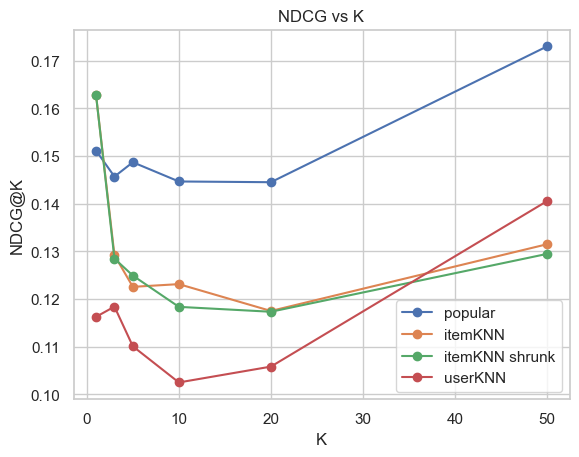

In [15]:
ks = [1, 3, 5, 10, 20, 50]
res = {'popular': [], 'itemKNN': [], 'itemKNN shrunk': [], 'userKNN': []}
for k in ks:
    for name, fn in [('popular', most_popular_reco), ('itemKNN', itemknn_reco),
                     ('itemKNN shrunk', itemknn_shrunk), ('userKNN', userknn_reco)]:
        m, _ = evaluate(fn, test_by_user, users_eval[:400], k=k)
        res[name].append(m['ndcg'])
for name, y in res.items():
    plt.plot(ks, y, marker='o', label=name)
plt.xlabel('K'); plt.ylabel('NDCG@K'); plt.legend(); plt.title('NDCG vs K'); plt.show()


## Задача 1. Curve NDCG vs. количество соседей

Постройте кривую NDCG@10 в зависимости от количества соседей `KNN_USERS` в user-based (например, 5, 10, 30, 50, 100, 200).

KNN_USERS=  5  NDCG@10=0.0933
KNN_USERS= 10  NDCG@10=0.0977
KNN_USERS= 30  NDCG@10=0.1025
KNN_USERS= 50  NDCG@10=0.1126
KNN_USERS=100  NDCG@10=0.1162
KNN_USERS=200  NDCG@10=0.1151


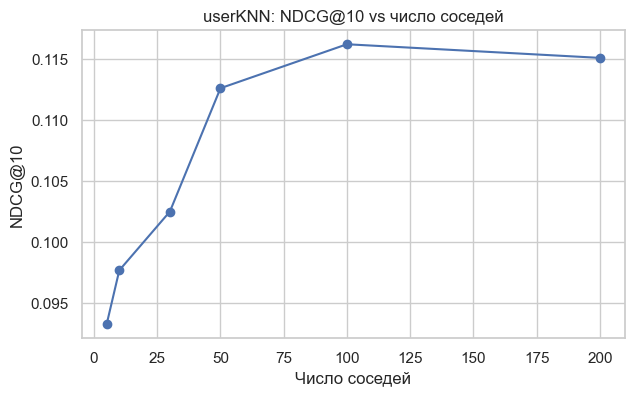

In [16]:
# YOUR CODE HERE
# для разных n постройте функцию userknn с nn соседей и посчитайте NDCG@10

def userknn_reco_n(u, k=10, n_neighbors=30):
    if u not in u2idx:
        return []
    ui = u2idx[u]
    sims = S_user[ui]
    n_avail = sims.size - 1  # диагональ уже обнулена, себя не берём
    n_neighbors = min(n_neighbors, n_avail)
    if n_neighbors <= 0:
        return []
    # argpartition не сортирует, поэтому соседей ещё раз упорядочиваем по sim
    cand = np.argpartition(-sims, n_neighbors - 1)[:n_neighbors]
    cand = cand[np.argsort(-sims[cand])]
    weights = sims[cand]
    scores = np.asarray(weights @ R[cand]).ravel()
    seen = R.getrow(ui).indices
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]


neighbor_grid = [5, 10, 30, 50, 100, 200]
ndcg_by_neighbors = []
for n in neighbor_grid:
    m, _ = evaluate(lambda u, k, n=n: userknn_reco_n(u, k, n), test_by_user, users_eval, k=10)
    ndcg_by_neighbors.append(m['ndcg'])
    print(f'KNN_USERS={n:3d}  NDCG@10={m["ndcg"]:.4f}')

plt.figure(figsize=(7, 4))
plt.plot(neighbor_grid, ndcg_by_neighbors, marker='o')
plt.xlabel('Число соседей')
plt.ylabel('NDCG@10')
plt.title('userKNN: NDCG@10 vs число соседей')
plt.show()

При маленьком `n` рекомендации шумные: один случайный сосед может перетянуть топ. При слишком большом в сумму попадают пользователи с околонулевой похожестью, и userKNN сползает к популярности. Обычно кривая растёт до нескольких десятков соседей и дальше выходит на плато.

## Задача 2. Диагностика цепочек

Для случайного пользователя выведите 5 объектов, у которых наибольший вклад в `itemknn_reco` (т.е. 5 объектов из истории, которые вытащили конкретную рекомендацию).

In [17]:
# YOUR CODE HERE
# Для конкретного пользователя u:
# 1) посчитайте scores;
# 2) для каждого top-3 рекомендованного item покажите top-5 «доноров» из истории.

rng = np.random.default_rng(RANDOM_STATE)
eligible = [u for u in users_eval if R.getrow(u2idx[u]).nnz >= 5]
u = int(rng.choice(eligible))
ui = u2idx[u]
seen = R.getrow(ui).indices

scores = S_item[:, seen].sum(axis=1).astype(float).copy()
scores[seen] = -np.inf
top3 = np.argsort(scores)[::-1][:3]

print(f'user_id={u}, объектов в истории: {len(seen)}')
for rank, item_idx in enumerate(top3, start=1):
    contrib = S_item[item_idx, seen]
    donor_order = np.argsort(contrib)[::-1][:5]
    print(f'\n#{rank} рекомендация item_id={item_ids[item_idx]}, score={scores[item_idx]:.4f}')
    for j_local in donor_order:
        j = seen[j_local]
        print(f'  donor item_id={item_ids[j]:5d}  similarity={contrib[j_local]:.4f}')

user_id=64, объектов в истории: 14

#1 рекомендация item_id=50, score=5.6643
  donor item_id=    1  similarity=0.6203
  donor item_id=  127  similarity=0.6033
  donor item_id=  100  similarity=0.6005
  donor item_id=  265  similarity=0.4752
  donor item_id=  275  similarity=0.4337

#2 рекомендация item_id=98, score=5.3775
  donor item_id=  100  similarity=0.5481
  donor item_id=  127  similarity=0.5070
  donor item_id=  265  similarity=0.5035
  donor item_id=    1  similarity=0.4940
  donor item_id=  527  similarity=0.4540

#3 рекомендация item_id=174, score=5.3681
  donor item_id=  265  similarity=0.5569
  donor item_id=    1  similarity=0.5240
  donor item_id=  385  similarity=0.4979
  donor item_id=  127  similarity=0.4972
  donor item_id=  527  similarity=0.4912


Скор кандидата в `itemknn_reco` - сумма cosine-похожестей на объекты из истории. Вклад донора `j` в рекомендацию `i` - это `S_item[i, j]`.

Если у топ-рекомендации почти весь скор сидит в одном-двух донорах, объяснение честное: «посмотрели X - рядом Y». Если вклады размазаны по десяткам слабых связей, цепочка уже неинтерпретируема, хотя сумма и вытаскивает объект в топ.

## Задача 3. Adjusted cosine (в кавычках)

Реализуйте mean-centering: перед counting-similarity вычтите среднюю строку каждого пользователя. Сравните с обычной itemKNN.

In [18]:
# YOUR CODE HERE
# 1) центрируйте матрицу построчно (по mean только по существующим значениям)
# 2) постройте новую similarity и оцените

# Решение ниже

Центрируем только наблюдаемые единицы: из каждой строки вычитаем среднее пользователя по его позитивам, нули матрицы не трогаем. Дальше обычный item-cosine.

In [19]:
R_c = R.tolil(copy=True)
for i in range(R_c.shape[0]):
    idx = R_c.rows[i]
    if not idx:
        continue
    vals = np.asarray(R_c.data[i], dtype=float)
    R_c.data[i] = (vals - vals.mean()).tolist()
R_c = R_c.tocsr()

Rn_items_c = normalize(R_c, norm='l2', axis=0)
S_item_centered = (Rn_items_c.T @ Rn_items_c).toarray()
np.fill_diagonal(S_item_centered, 0.0)


def itemknn_centered(u, k=10):
    if u not in u2idx:
        return []
    seen = R.getrow(u2idx[u]).indices
    if len(seen) == 0:
        return []
    scores = S_item_centered[:, seen].sum(axis=1).astype(float).copy()
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]


m_centered, reco_centered = evaluate(itemknn_centered, test_by_user, users_eval, k=10)
cmp = pd.DataFrame({'itemKNN': m_itemknn, 'itemKNN centered': m_centered}).T.round(4)
print(cmp)

                  precision  recall      hr     mrr    ndcg     map
itemKNN              0.1140  0.0494  0.3140  0.2087  0.1231  0.0798
itemKNN centered     0.0163  0.0033  0.1047  0.0263  0.0139  0.0044


На бинарной матрице позитивов у всех наблюдаемых значений стоит 1, поэтому среднее пользователя тоже 1, и центрирование обнуляет всю матрицу. Чтобы приём имел смысл, в `R` нужно класть сами рейтинги, а не индикатор `rating >= 4`:

In [20]:
rows_r = train['user_id'].map(u2idx)
cols_r = train['item_id'].map(i2idx)
mask = rows_r.notna() & cols_r.notna()
R_rating = csr_matrix(
    (train.loc[mask, 'rating'].astype(float).values,
     (rows_r[mask].astype(int).values, cols_r[mask].astype(int).values)),
    shape=R.shape,
)

R_adj = R_rating.tolil(copy=True)
for i in range(R_adj.shape[0]):
    idx = R_adj.rows[i]
    if not idx:
        continue
    vals = np.asarray(R_adj.data[i], dtype=float)
    R_adj.data[i] = (vals - vals.mean()).tolist()
R_adj = R_adj.tocsr()

Rn_adj = normalize(R_adj, norm='l2', axis=0)
S_adj = (Rn_adj.T @ Rn_adj).toarray()
np.fill_diagonal(S_adj, 0.0)


def itemknn_adjusted(u, k=10):
    if u not in u2idx:
        return []
    seen = R.getrow(u2idx[u]).indices
    if len(seen) == 0:
        return []
    scores = S_adj[:, seen].sum(axis=1).astype(float).copy()
    scores[seen] = -np.inf
    order = np.argsort(scores)[::-1]
    return [item_ids[i] for i in order if scores[i] > -np.inf][:k]


m_adj, _ = evaluate(itemknn_adjusted, test_by_user, users_eval, k=10)
print(pd.DataFrame({'itemKNN binary': m_itemknn, 'adjusted cosine': m_adj}).T.round(4))

                 precision  recall      hr     mrr    ndcg     map
itemKNN binary       0.114  0.0494  0.3140  0.2087  0.1231  0.0798
adjusted cosine      0.086  0.0285  0.2558  0.1659  0.0931  0.0608


Adjusted cosine убирает пользовательский сдвиг: "щедрый" пользователь с пятёрками перестаёт быть похожим на всех подряд только потому, что ставит высокие оценки. На бинарных кликах центрировать нечего - там работает обычный cosine или Jaccard.

## 11. Итоги

- itemKNN обычно лучше userKNN на MovieLens.
- Shrinking и Jaccard дают лучший coverage.
- Cold-start остаётся проблемой.
